# Respiratory Disease Detection from Lung Sounds

### Abstract
This project builds an automatic classifier for respiratory diseases using lung sound recordings. The goal is to detect four conditions from audio: normal breathing, crackles, wheezes, and a mix of both. This is useful in clinical settings where a doctor listens to a patient's chest with a stethoscope — the model attempts to do the same thing automatically.

### Dataset
The ICBHI 2017 Respiratory Sound Database is used in this project, which contains 920 recordings from 126 patients collected using 4 different stethoscope types. The dataset includes 6,898 annotated breath cycles labeled by expert clinicians.

Source: https://kaggle.com/datasets/vbookshelf/respiratory-sound-database
Classes: normal, crackles, wheezes, both
Sample rate: 4000 Hz
Split: 60% train / 40% test (patient-independent)
### Pipeline
Parse annotations and build a dataframe of breath cycles
Apply a bandpass filter (100–1999 Hz) to remove noise
Segment each cycle, pad or trim to 4 seconds
Convert to Mel spectrogram (128 bins, 4000 Hz sample rate)
Train a ResNet50V2 pretrained on ImageNet using fine-tuning
Use focal loss to handle class imbalance
### Model
Architecture : ResNet50V2 pretrained on ImageNet
Framework : TensorFlow / Keras
Loss : Focal loss (gamma=2.0, alpha=0.25)
Optimizer : Adam
Input shape : (128, 128, 3) — Mel spectrogram as image
### Evaluation Metric
The official ICBHI Score is defined as:

ICBHI Score = average of (Sensitivity + Specificity) / 2
              across all 4 classes
This metric is used in all published work on this dataset, making our results directly comparable to the literature.

### References
Rocha et al. (2019) — "An open access database for the evaluation of respiratory sound classification algorithms" https://doi.org/10.1016/j.pnpbp.2018.09.015

Gairola et al. (2021) — "RespiNet: A Deep Learning Approach for Respiratory Sound Classification" https://arxiv.org/abs/2011.00196

Moummad & Farrugia (2023) — "Supervised Contrastive Learning for Respiratory Sound Classification" — WASPAA 2023 https://arxiv.org/abs/2210.16192

Chen et al. (2022) — "CNN-LSTM for Respiratory Sound Classification" https://www.ncbi.nlm.nih.gov/pmc/articles/PMC8838187/

## Step 1 : load dataset

Importing all the libraries needed for the project.

In [1]:
import kagglehub
import os
import librosa
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from scipy.signal import butter, filtfilt

C:\Users\hp\RespDisease\RespDisease\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setting up local project folders (replaces Google Drive mount)

In [2]:
BASE_DIR = os.path.join(os.getcwd(), "icbhi_project")

os.makedirs(os.path.join(BASE_DIR, "cycles"), exist_ok=True)
os.makedirs(os.path.join(BASE_DIR, "spectrograms"), exist_ok=True)
os.makedirs(os.path.join(BASE_DIR, "models"), exist_ok=True)

Downloading the ICBHI 2017 Respiratory Sound Database from Kaggle

In [3]:
path = kagglehub.dataset_download("vbookshelf/respiratory-sound-database")

In [4]:
print(path)

C:\Users\hp\.cache\kagglehub\datasets\vbookshelf\respiratory-sound-database\versions\2


loading one wav file to confirm the dataset is accessible

In [5]:
dataset_path = path

#code imported from stack overflow to load wave files
for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.endswith(".wav"):

            wav_path = os.path.join(root, file)
            audio, sr = librosa.load(wav_path, sr=None)

            print("File:", wav_path)
            print("Sample rate:", sr)
            print("Audio shape:", audio.shape)

            break

File: C:\Users\hp\.cache\kagglehub\datasets\vbookshelf\respiratory-sound-database\versions\2\Respiratory_Sound_Database\Respiratory_Sound_Database\audio_and_txt_files\101_1b1_Al_sc_Meditron.wav
Sample rate: 44100
Audio shape: (882000,)


Plotting the raw audio signal of one recording to check it loaded correctly

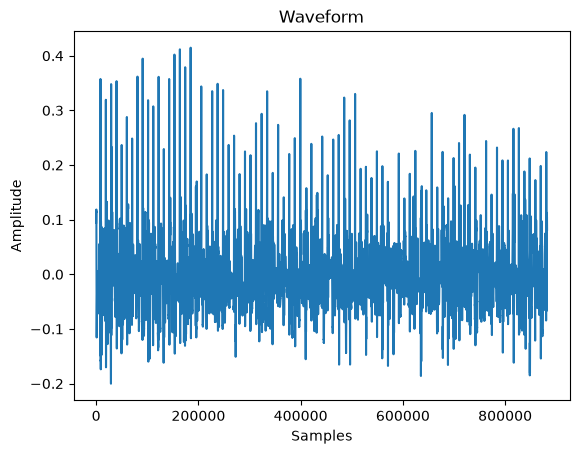

In [6]:
plt.plot(audio)
plt.title("Waveform")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.show()

Opening the demographic_info.txt file to understand its structure. This file contains patient information like age, sex, and BMI.

In [7]:
txt_file = os.path.join(dataset_path, "demographic_info.txt")
with open(txt_file, "r") as file:
    content = file.read()
    print(content)


101 3 F NA 19 99
102 0.75 F NA 9.8 73
103 70 F 33 NA NA
104 70 F 28.47 NA NA
105 7 F NA 32 135
106 73 F 21 NA NA
107 75 F 33.7 NA NA
108 3 M NA NA NA
109 84 F 33.53 NA NA
110 75 M 25.21 NA NA
111 63 M 28.4 NA NA
112 60 M 22.86 NA NA
113 58 M 28.41 NA NA
114 77 M 23.12 NA NA
115 0.58 M NA 7.14 64
116 56 M 28.58 NA NA
117 68 M 24.4 NA NA
118 81 M 36.76 NA NA
119 2 F NA 15.2 94
120 78 M 35.14 NA NA
121 13 F NA 65 170
122 66 M 33 NA NA
123 5 M NA 25 125
124 65 M 29.07 NA NA
125 14 M NA 62 170
126 1 F NA 10.18 80
127 2 M NA 12.6 98
128 65 F 24.3 NA NA
129 6 M NA 23 119
130 85 F 17.1 NA NA
131 3 M NA 14 97
132 71 M 34 NA NA
133 68 M 27.4 NA NA
134 61 M 32 NA NA
135 70 M 21 NA NA
136 5 M NA 16.2 110
137 4 M NA 18 104
138 56 F 21.6 NA NA
139 61 M 28.68 NA NA
140 79 F 23 NA NA
141 66 M 22.4 NA NA
142 78 M 26.1 NA NA
143 0.25 F NA 8.24 68
144 3 M NA 16.7 100
145 69 M 23.4 NA NA
146 67 M 28 NA NA
147 77 M 25.7 NA NA
148 4 M NA 33 110
149 0.67 M NA 9.5 70
150 0.67 F NA 8.12 74
151 75 M 28.4 NA NA

looping through all annotation (.txt) files in the dataset. Each line in a txt file represents one breath cycle with:

start and end timestamps (in seconds)
crackles label (0 or 1)
wheezes label (0 or 1)
Combining crackles and wheezes into one label:

0,0 - normal
1,0 - crackles
0,1 - wheezes
1,1 - both
The result is a dataframe where each row is one breath cycle.

In [8]:
data = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:

        # skip anything that is not an annotation file
        if not file.endswith(".txt"):
            continue

        # skip the demographic file
        if file == "demographic_info.txt":
            continue

        # build full path to the txt and wav files
        txt_path = os.path.join(root, file)
        wav_file = file.replace(".txt", ".wav")
        wav_path = os.path.join(root, wav_file)

        # skip if the wav file does not exist
        if not os.path.exists(wav_path):
            continue

        # get patient id from filename
        patient_id = file.split("_")[0]

        # read the annotation file line by line
        with open(txt_path, "r") as f:
            for line in f:

                # split the line into parts
                parts = line.strip().split()

                # skip empty lines
                if len(parts) < 4:  #4 values (start end crackles wheezes)
                    continue

                # skip lines that don't have 0 or 1 in columns 2 and 3
                if parts[2] not in ("0", "1"):
                    continue
                if parts[3] not in ("0", "1"):
                    continue

                # read the values
                start    = float(parts[0])
                end      = float(parts[1])
                crackles = int(parts[2])
                wheezes  = int(parts[3])

                # assign a label based on crackles and wheezes
                if crackles == 0 and wheezes == 0:
                    label = "normal"
                elif crackles == 1 and wheezes == 0:
                    label = "crackles"
                elif crackles == 0 and wheezes == 1:
                    label = "wheezes"
                else:
                    label = "both"

                data.append([patient_id, wav_path, start, end, label])

df = pd.DataFrame(
    data,
    columns=["patient_id", "file_path", "start", "end", "label"]
)

print("Total breath cycles:", len(df))
print()
print(df["label"].value_counts())

Total breath cycles: 6898

label
normal      3642
crackles    1864
wheezes      886
both         506
Name: count, dtype: int64


## Step2 : Preprocessing

Picking the first row of the dataframe and extract its breath cycle from the audio file.

Converting the start and end timestamps from seconds to sample indices:

sample index = time in seconds × sample rate
e.g. start=0.036s × 4000 Hz = sample 144

In [9]:
# pick the first row from your dataframe as a test
row = df.iloc[0]

# load the full wav file at 4000 Hz
full_audio, sr = librosa.load(row["file_path"], sr=4000)

# convert start and end times from seconds to sample indices
start_sample = int(row["start"] * sr)
end_sample   = int(row["end"]   * sr)

# cut out the breath cycle
cycle_audio = full_audio[start_sample : end_sample]

print("Sample rate:", sr)
print("Cycle duration:", round(row["end"] - row["start"], 2), "seconds")
print("Cycle samples:", len(cycle_audio))

Sample rate: 4000
Cycle duration: 0.54 seconds
Cycle samples: 2172


Applying a bandpass filter to keep only the frequencies between 100 and 1999 Hz.

This removes two types of noise:

below 100 Hz → heartbeat and body movement noise
above 2000 Hz → stethoscope cable noise and electrical interference
All useful lung sounds (normal breathing, crackles, wheezes) live between 100 and 2000 Hz.

Using 1999 instead of 2000 because scipy requires the upper cutoff to be strictly less than the Nyquist frequency (sample_rate / 2). At 4000 Hz sample rate, Nyquist = 2000 Hz exactly. Passing 2000 would cause a ValueError — 1999 avoids this with no practical difference.

In [10]:
def bandpass_filter(audio, low_freq, high_freq, sample_rate):
    nyquist      = sample_rate / 2
    low          = low_freq  / nyquist
    high         = high_freq / nyquist
    b, a         = butter(4, [low, high], btype="band")
    filtered     = filtfilt(b, a, audio)
    return filtered

# apply to the cycle that's been cut
filtered_audio = bandpass_filter(cycle_audio, 100, 1999, sr)

print("Filtered audio length:", len(filtered_audio))

Filtered audio length: 2172


Plotting the audio signal before and after applying the bandpass filter.

The amplitude dropped after filtering since the low frequency heartbeat noise waw removed.

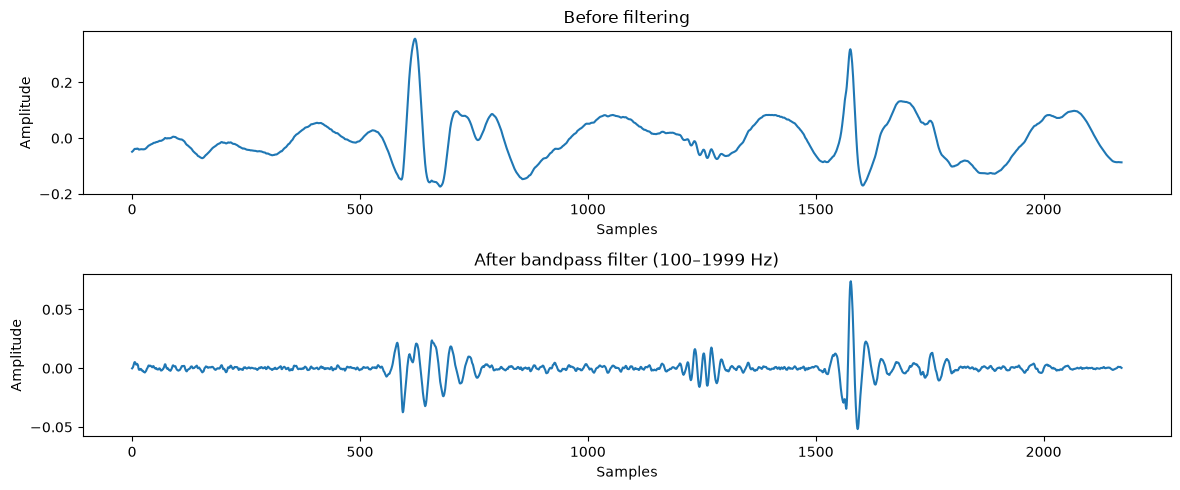

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5))

axes[0].plot(cycle_audio)
axes[0].set_title("Before filtering")
axes[0].set_xlabel("Samples")
axes[0].set_ylabel("Amplitude")

axes[1].plot(filtered_audio)
axes[1].set_title("After bandpass filter (100–1999 Hz)")
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

## Step 3 : Breath cycle

Looping through every row in the dataframe and:

1. load the full wav file
2. cut out the breath cycle using start and end timestamps
3. skip cycles shorter than 0.5 seconds (too short to be useful)
4. apply the bandpass filter (100–1999 Hz)
pad or trim to exactly 4 seconds (16000 samples)
    1. if too short - repeat the signal to fill 4 seconds
    2. if too long - cut at 4 seconds
5. save as a .npy file on Google Drive

In [12]:
output_folder = os.path.join(BASE_DIR, "cycles")
os.makedirs(output_folder, exist_ok=True)

# fixed length: 4 seconds at 4000 Hz
SAMPLE_RATE    = 4000
CYCLE_LENGTH   = 4 * SAMPLE_RATE  # = 16000 samples

def pad_or_trim(audio, target_length):
    # if too short — repeat the signal until it fills the target length
    if len(audio) < target_length:
        # how many times needed to repeat it
        repeats    = (target_length // len(audio)) + 1
        audio      = np.tile(audio, repeats)

    # trim to exactly target length
    audio = audio[:target_length]
    return audio

for index, row in df.iterrows():

    # load the full wav file
    full_audio, sr = librosa.load(row["file_path"], sr=SAMPLE_RATE)

    # cut the breath cycle using start and end timestamps
    start_sample = int(row["start"] * sr)
    end_sample   = int(row["end"]   * sr)
    cycle_audio  = full_audio[start_sample : end_sample]

    # skip cycles that are too short to be useful (less than 0.5 seconds)
    if len(cycle_audio) < SAMPLE_RATE * 0.5:
        continue

    # apply bandpass filter
    cycle_audio = bandpass_filter(cycle_audio, 100, 1999, sr)

    # pad or trim to fixed length
    cycle_audio = pad_or_trim(cycle_audio, CYCLE_LENGTH)

    # save as a .npy file named by its index
    save_path = os.path.join(output_folder, f"cycle_{index}.npy")
    np.save(save_path, cycle_audio)

## Step 4 : feature extraction

A regular spectrogram shows frequency vs time. A Mel spectrogram does the same thing but spaces the frequency axis the way human hearing works

Defining a function that converts a 1D audio signal into a 2D Mel spectrogram.

A Mel spectrogram shows how the energy of the sound is distributed across frequencies over time — like a heatmap where:

* x axis = time
* y axis = frequency (in Mel scale)
* color = energy (bright = loud, dark = quiet)
This turns each audio cycle into an image that the CNN can learn from.

Parameters:

* n_mels=128 - 128 frequency bins on the y axis
* n_fft=1024 - window size for frequency analysis
* hop_length=512 - step between windows (512 = 50% overlap)
* power_to_db - converts energy to decibels (log scale)

In [13]:
SAMPLE_RATE = 4000
N_MELS      = 128
N_FFT       = 1024
HOP_LENGTH  = 512

def compute_mel_spectrogram(audio):

    mel = librosa.feature.melspectrogram(
        y          = audio,
        sr         = SAMPLE_RATE,
        n_mels     = N_MELS,
        n_fft      = N_FFT,
        hop_length = HOP_LENGTH
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)

    return mel_db

Loading one saved cycle and computing its Mel spectrogram to verify the function works correctly before applying it to all cycles.

In [14]:
output_folder = os.path.join(BASE_DIR, "cycles")
test_audio = np.load(os.path.join(output_folder, "cycle_0.npy"))

mel = compute_mel_spectrogram(test_audio)

print("Audio shape :", test_audio.shape)
print("Spectrogram shape:", mel.shape)

Audio shape : (16000,)
Spectrogram shape: (128, 32)


An audio array with a shape of 16000 typically represents exactly one second of monophonic audio recorded at a (16,000 \text{ Hz}) sampling rate.



Plotting the Mel spectrogram of one breath cycle to visually inspect it.

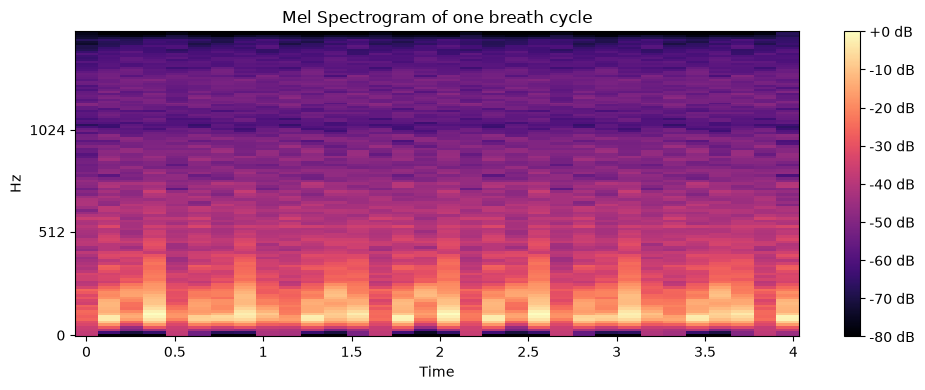

In [15]:
plt.figure(figsize=(10, 4))

librosa.display.specshow(
    mel,
    sr         = SAMPLE_RATE,
    hop_length = HOP_LENGTH,
    x_axis     = "time",
    y_axis     = "mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram of one breath cycle")
plt.tight_layout()
plt.show()

Looping through every saved cycle and convert it to a Mel spectrogram.

In [16]:
spec_folder = os.path.join(BASE_DIR, "spectrograms")
os.makedirs(spec_folder, exist_ok=True)

label_map = {
    "normal"   : 0,
    "crackles" : 1,
    "wheezes"  : 2,
    "both"     : 3
}

labels      = []
saved_names = []
skipped     = 0

for index, row in df.iterrows():

    cycle_path = os.path.join(output_folder, f"cycle_{index}.npy")

    if not os.path.exists(cycle_path):
        continue

    # try to load — skip if file is corrupted
    try:
        audio = np.load(cycle_path)
    except Exception as e:
        skipped += 1
        continue

    mel       = compute_mel_spectrogram(audio)
    save_path = os.path.join(spec_folder, f"spec_{index}.npy")
    np.save(save_path, mel)

    labels.append(label_map[row["label"]])
    saved_names.append(f"spec_{index}.npy")

print("Total spectrograms saved:", len(saved_names))
print("Corrupted files skipped :", skipped)

Total spectrograms saved: 6857
Corrupted files skipped : 0


Combining the filenames and labels into a dataframe and save it as a CSV file to Google Drive.

In [17]:
specs_df = pd.DataFrame({"filename" : saved_names,"label":labels})

specs_df.to_csv(os.path.join(BASE_DIR, "labels.csv"),index=False)

print(specs_df["label"].value_counts())

label
0    3608
1    1861
2     882
3     506
Name: count, dtype: int64


Loading one spectrogram back from disk to confirm it was saved correctly and check its shape.

In [18]:
test_spec = np.load(os.path.join(spec_folder, "spec_0.npy"))

print("Spectrogram shape:", test_spec.shape)

Spectrogram shape: (128, 32)


## Step 5 : class imbalance

Patient ID split

In [19]:
specs_df = pd.read_csv(os.path.join(BASE_DIR, "labels.csv"))

specs_df["patient_id"] = specs_df["filename"].apply(
    lambda x: df.loc[int(x.replace("spec_", "").replace(".npy", "")), "patient_id"]
)

all_patients = specs_df["patient_id"].unique()

train_patients, test_patients = train_test_split(
    all_patients,
    test_size    = 0.4,
    random_state = 42
)

train_df = specs_df[specs_df["patient_id"].isin(train_patients)]
test_df  = specs_df[specs_df["patient_id"].isin(test_patients)]

print("Train cycles:", len(train_df))
print("Test cycles :", len(test_df))

Train cycles: 4496
Test cycles : 2361


Saving the train and test splits as CSV files to Google Drive.

In [20]:
train_df.to_csv(os.path.join(BASE_DIR, "train_split.csv"), index=False)
test_df.to_csv(os.path.join(BASE_DIR, "test_split.csv"),   index=False)

print("Train split saved:", len(train_df), "cycles")
print("Test split saved :", len(test_df),  "cycles")

Train split saved: 4496 cycles
Test split saved : 2361 cycles


Creating a data generator that loads spectrograms in small batches instead of loading everything into RAM at once.

In [21]:
train_df = pd.read_csv(os.path.join(BASE_DIR, "train_split.csv"))
test_df  = pd.read_csv(os.path.join(BASE_DIR, "test_split.csv"))

class SpectrogramGenerator(tf.keras.utils.Sequence):

    def __init__(self, dataframe, batch_size=32):
        self.dataframe  = dataframe.reset_index(drop=True)
        self.batch_size = batch_size

    def __len__(self):
        return len(self.dataframe) // self.batch_size

    def __getitem__(self, batch_index):

        start = batch_index * self.batch_size
        end   = start + self.batch_size
        batch = self.dataframe.iloc[start:end]

        X = []
        y = []

        for _, row in batch.iterrows():

            spec_path = os.path.join(spec_folder, row["filename"])
            spec      = np.load(spec_path)
            spec      = np.resize(spec, (128, 128))
            spec      = np.stack([spec, spec, spec], axis=-1)

            X.append(spec)
            y.append(row["label"])

        return np.array(X), np.array(y)

train_generator = SpectrogramGenerator(train_df, batch_size=32)
test_generator  = SpectrogramGenerator(test_df,  batch_size=32)

print("Train batches per epoch:", len(train_generator))
print("Test batches per epoch :", len(test_generator))

Train batches per epoch: 140
Test batches per epoch : 73


## Step 6 : training model on resnet50v2

Using ResNet50V2 pretrained on ImageNet as our base model.

The model has two parts:

1. base model - ResNet50V2 frozen (weights not updated during phase 1)
2. custom head - GlobalAveragePooling - Dropout - Dense(4 classes)

In [22]:
base_model = ResNet50V2(
    include_top  = False,
    weights      = "imagenet",
    input_shape  = (128, 128, 3)
)

base_model.trainable = False

inputs  = tf.keras.Input(shape=(128, 128, 3))
x       = base_model(inputs, training=False)
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.summary()

       0/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/94668760 ━━━━━━━━━━━━━━━━━━━━ 6:50 4us/step

   49152/94668760 ━━━━━━━━━━━━━━━━━━━━ 4:07 3us/step

   81920/94668760 ━━━━━━━━━━━━━━━━━━━━ 3:27 2us/step

  139264/94668760 ━━━━━━━━━━━━━━━━━━━━ 2:52 2us/step

...

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,572,996 (89.92 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,564,800 (89.89 MB)

Focal loss handles class imbalance by down-weighting easy examples.

gamma=2.0 = how much to down-weight easy examples (standard value) alpha=0.25 = overall loss scaling factor

In [23]:
def focal_loss(gamma=2.0, alpha=0.25):

    def loss_fn(y_true, y_pred):

        ce    = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
        p_t   = tf.exp(-ce)
        loss  = alpha * (1 - p_t) ** gamma * ce

        return loss

    return loss_fn

Compiling the model with focal loss and train for up to 20 epochs.

Callbacks:

* ModelCheckpoint - saves the best model weights automatically
* EarlyStopping - stops training if val_accuracy does not improve for 5 consecutive epochs to avoid wasting time

In [24]:
model.compile(
    optimizer = Adam(learning_rate=1e-4),
    loss      = focal_loss(gamma=2.0, alpha=0.25),
    metrics   = ["accuracy"]
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath       = os.path.join(BASE_DIR, "models", "best_model.keras"),
    monitor        = "val_accuracy",
    save_best_only = True,
    verbose        = 1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor  = "val_accuracy",
    patience = 5,
    verbose  = 1
)

history = model.fit(
    train_generator,
    epochs          = 20,
    validation_data = test_generator,
    callbacks       = [checkpoint, early_stop]
)

C:\Users\hp\RespDisease\RespDisease\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


  1/140 ━━━━━━━━━━━━━━━━━━━━ 31:43 14s/step - accuracy: 0.4062 - loss: 41.4959

  2/140 ━━━━━━━━━━━━━━━━━━━━ 1:13 531ms/step - accuracy: 0.3750 - loss: 44.7334

  3/140 ━━━━━━━━━━━━━━━━━━━━ 1:12 532ms/step - accuracy: 0.2708 - loss: 56.4881

...

139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 971ms/step - accuracy: 0.3577 - loss: 35.1530

140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 974ms/step - accuracy: 0.3578 - loss: 35.0470


Epoch 6: val_accuracy did not improve from 0.56464


140/140 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.3578 - loss: 35.0470 - val_accuracy: 0.5385 - val_loss: 6.7321


Epoch 6: early stopping


Unfreezing the entire ResNet and fine-tune all layers together at a much lower learning rate.

In [25]:
train_generator = SpectrogramGenerator(train_df, batch_size=64)
test_generator  = SpectrogramGenerator(test_df,  batch_size=64)

base_model.trainable = True

model.compile(
    optimizer = Adam(learning_rate=1e-5),
    loss      = focal_loss(gamma=2.0, alpha=0.25),
    metrics   = ["accuracy"]
)

early_stop_2 = tf.keras.callbacks.EarlyStopping(
    monitor  = "val_accuracy",
    patience = 3,
    verbose  = 1
)

checkpoint_2 = tf.keras.callbacks.ModelCheckpoint(
    filepath       = os.path.join(BASE_DIR, "models", "best_model_phase2.keras"),
    monitor        = "val_accuracy",
    save_best_only = True,
    verbose        = 1
)

history_2 = model.fit(
    train_generator,
    epochs          = 10,
    validation_data = test_generator,
    callbacks       = [checkpoint_2, early_stop_2]
)

Epoch 1/10


C:\Users\hp\RespDisease\RespDisease\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 1/70 ━━━━━━━━━━━━━━━━━━━━ 51:03 44s/step - accuracy: 0.3594 - loss: 0.2807

 2/70 ━━━━━━━━━━━━━━━━━━━━ 5:43 5s/step - accuracy: 0.3125 - loss: 0.2979  

 3/70 ━━━━━━━━━━━━━━━━━━━━ 5:17 5s/step - accuracy: 0.2812 - loss: 0.3132

...

69/70 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.9629 - loss: 0.0174 

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9634 - loss: 0.0173


Epoch 8: val_accuracy did not improve from 0.50608


70/70 ━━━━━━━━━━━━━━━━━━━━ 653s 9s/step - accuracy: 0.9634 - loss: 0.0173 - val_accuracy: 0.5056 - val_loss: 0.1988


Epoch 8: early stopping


Saving labels to CSV

In [26]:
specs_df = pd.DataFrame({"filename" : saved_names,"label" : labels})
specs_df.to_csv(os.path.join(BASE_DIR, "labels.csv"),index=False)
print(specs_df["label"].value_counts())

label
0    3608
1    1861
2     882
3     506
Name: count, dtype: int64


Splitting patients into 60% train and 40% test and save both splits as CSV files.

In [27]:
specs_df["patient_id"] = specs_df["filename"].apply(
    lambda x: df.loc[int(x.replace("spec_", "").replace(".npy", "")), "patient_id"]
)

all_patients = specs_df["patient_id"].unique()

train_patients, test_patients = train_test_split(
    all_patients,
    test_size    = 0.4,
    random_state = 42
)

train_df = specs_df[specs_df["patient_id"].isin(train_patients)]
test_df  = specs_df[specs_df["patient_id"].isin(test_patients)]

train_df.to_csv(os.path.join(BASE_DIR, "train_split.csv"), index=False)
test_df.to_csv(os.path.join(BASE_DIR, "test_split.csv"),   index=False)

print("Train cycles:", len(train_df))
print("Test cycles :", len(test_df))

Train cycles: 4496
Test cycles : 2361


## Step 8 : Evaluation

Loading the best model

In [28]:
label_names = ["normal", "crackles", "wheezes", "both"]

model = tf.keras.models.load_model(
    os.path.join(BASE_DIR, "models", "best_model_phase2.keras"),
    custom_objects = {"loss_fn": focal_loss(gamma=2.0, alpha=0.25)}
)

Running the model on every batch of the test generator and collecting all predictions and true labels.

np.argmax converts model output probabilities to a class index

In [29]:
all_predictions = []
all_true_labels = []

for batch_index in range(len(test_generator)):

    X_batch, y_batch      = test_generator[batch_index]
    predictions           = model.predict(X_batch, verbose=0)
    predicted_classes     = np.argmax(predictions, axis=1)

    all_predictions.extend(predicted_classes)
    all_true_labels.extend(y_batch)

all_predictions = np.array(all_predictions)
all_true_labels = np.array(all_true_labels)

print("Total predictions:", len(all_predictions))

Total predictions: 2304


A confusion matrix shows how many cycles were correctly classified and which classes get confused with each other.

* Each row = true label
* Each column = predicted label
* Diagonal = correct predictions (they need to be high)
Off-diagonal = mistakes (they need to be low)

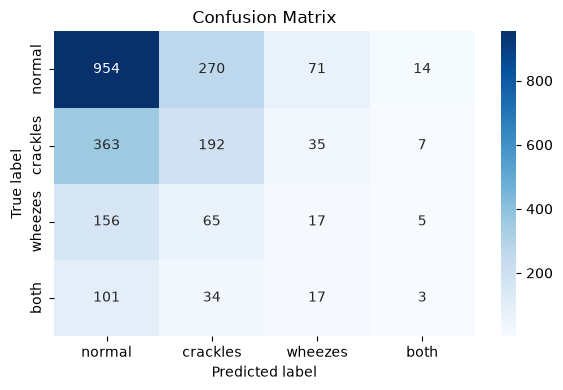

In [30]:
cm = confusion_matrix(all_true_labels, all_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot       = True,
    fmt         = "d",
    cmap        = "Blues",
    xticklabels = label_names,
    yticklabels = label_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

The classification report shows precision, recall and F1 score for each class individually.

In [31]:
print("Classification Report:")
print()
print(classification_report(
    all_true_labels,
    all_predictions,
    target_names = label_names
))

Classification Report:

              precision    recall  f1-score   support

      normal       0.61      0.73      0.66      1309
    crackles       0.34      0.32      0.33       597
     wheezes       0.12      0.07      0.09       243
        both       0.10      0.02      0.03       155

    accuracy                           0.51      2304
   macro avg       0.29      0.28      0.28      2304
weighted avg       0.45      0.51      0.47      2304



The ICBHI score is the official evaluation metric for this dataset. It is defined as the average of (sensitivity + specificity) / 2 across all 4 classes.

* sensitivity = how many sick cycles we correctly detected (true positive rate)
* specificity = how many healthy cycles we correctly rejected (true negative rate)

In [32]:
def compute_icbhi_score(true_labels, predictions, num_classes=4):

    sensitivities = []
    specificities = []

    for class_index in range(num_classes):

        tp = np.sum((true_labels == class_index) & (predictions == class_index))
        fn = np.sum((true_labels == class_index) & (predictions != class_index))
        fp = np.sum((true_labels != class_index) & (predictions == class_index))
        tn = np.sum((true_labels != class_index) & (predictions != class_index))

        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

        sensitivities.append(sensitivity)
        specificities.append(specificity)

        print(f"{label_names[class_index]:10s} — sensitivity: {sensitivity:.3f}  specificity: {specificity:.3f}")

    icbhi_score = np.mean([(s + sp) / 2 for s, sp in zip(sensitivities, specificities)])

    print()
    print(f"ICBHI Score: {icbhi_score * 100:.2f}%")

    return icbhi_score

icbhi_score = compute_icbhi_score(all_true_labels, all_predictions)

normal     — sensitivity: 0.729  specificity: 0.377
crackles   — sensitivity: 0.322  specificity: 0.784
wheezes    — sensitivity: 0.070  specificity: 0.940
both       — sensitivity: 0.019  specificity: 0.988

ICBHI Score: 52.86%


Plotting the accuracy and loss over epochs for both the training set and the validation set.

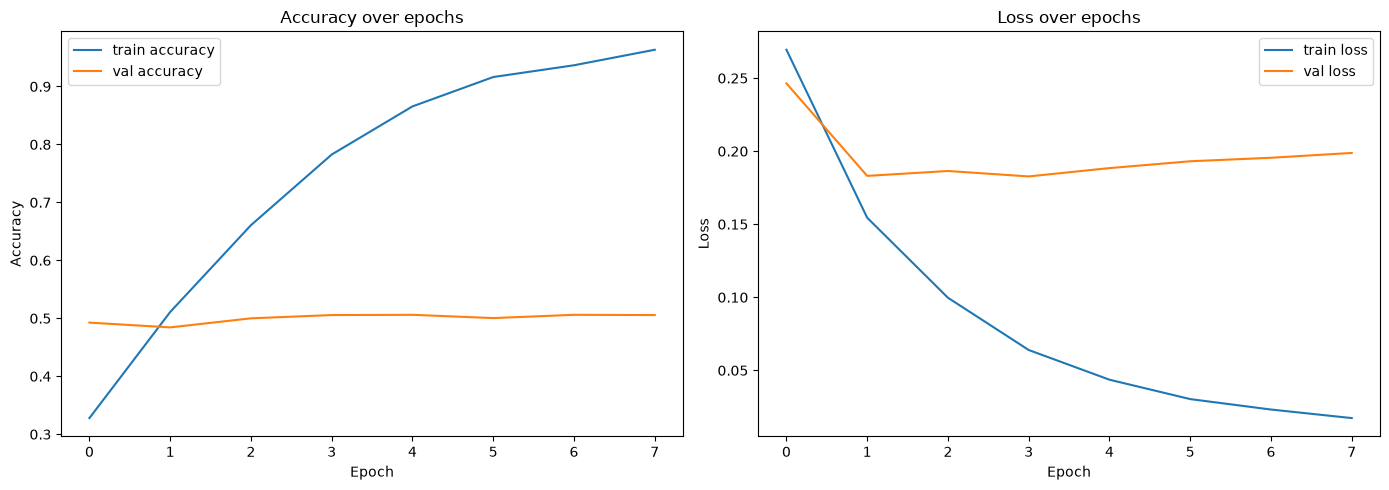

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_2.history["accuracy"],     label="train accuracy")
axes[0].plot(history_2.history["val_accuracy"], label="val accuracy")
axes[0].set_title("Accuracy over epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_2.history["loss"],     label="train loss")
axes[1].plot(history_2.history["val_loss"], label="val loss")
axes[1].set_title("Loss over epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## Conclusion
### What the model learned
The model successfully learned to distinguish respiratory sound patterns from Mel spectrograms, achieving an ICBHI Score of 52.86% on the official 60/40 patient-independent split.

### Training curves
The training curves reveal a clear overfitting problem:

* train accuracy reached 96% by epoch 8
* val accuracy stayed flat around 48–51%
* train loss dropped to near 0 while val loss increased
This means the model memorized the training data instead of generalizing to unseen patients.

### Classification report
The model performed very differently across the 4 classes:

* normal - best performance (precision=0.61, recall=0.73)
* crackles - weak performance (precision=0.34, recall=0.32)
* wheezes - poor performance (precision=0.12, recall=0.07)
* both - almost no detection (precision=0.10, recall=0.02)
This is directly caused by class imbalance — normal has 1309 test samples while both has only 155. The model defaulted to predicting normal for most inputs.

### Confusion matrix
The confusion matrix confirms this:

* 954 out of 1309 normal cycles correctly identified
* 363 crackles cycles were misclassified as normal
* 156 wheezes cycles were misclassified as normal
* 101 both cycles were misclassified as normal
The model is biased toward predicting normal (the majority class).

### ICBHI Score: 52.86%
This is above the random baseline (25% for 4 classes) and comparable to early published results on this dataset (2018-2019). State of the art results reach 79-85% — showing clear room for improvement.

### What could improve results
1. Fixing np.resize - using proper image resizing (tf.image.resize)
2. Stronger augmentation - SpecAugment, time shift, pitch shift
3. Deeper class balancing - oversample minority classes (SMOTE)
4. Lighter model - MobileNetV2 overfits less on small datasets
5. Larger dataset - combine ICBHI with other respiratory databases